# 02 — Hull-White rate simulation and future revaluation

**Questions 2 and 3 of the project:** how could interest rates evolve, and what would the swaps be worth in each simulated future state?

1. Simulate the one-factor Hull-White model exactly on the portfolio's time grid.
2. Check the simulation against its analytic moments, its mean-reversion speed and the martingale property.
3. Revalue every swap on every path and date (the MtM cube) and aggregate it by netting set.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
%matplotlib inline

from src.config import BASE_SIMULATION, CURVE_FILE, HW_PARAMS, PORTFOLIO_FILE
from src.curves import load_treasury_curve
from src.instruments import load_portfolio
from src.plotting import plot_mtm_fan, plot_rate_paths
from src.rate_models import phi_adjustment
from src.simulation import build_time_grid, netting_set_mtm, revalue_portfolio, simulate_paths, time_index
from src.swap_pricer import swap_mtm
from src.validation import martingale_table, percentile_profile, rate_distribution_table

pd.set_option('display.float_format', '{:,.6f}'.format)
curve = load_treasury_curve(CURVE_FILE)
portfolio = load_portfolio(PORTFOLIO_FILE)

## 1. The model

$$dr = (\theta(t) - a r)\,dt + \sigma\,dW, \qquad r(t) = x(t) + \varphi(t), \qquad dx = -a x\,dt + \sigma\,dW,\; x(0)=0$$

$\varphi(t) = f(0,t) + \frac{\sigma^2}{2a^2}(1-e^{-at})^2$ is chosen so the model reproduces today's curve. Bond prices are closed-form in $x(t)$:

$$P(t,T) = \frac{P(0,T)}{P(0,t)}\exp\Big(-B x(t) - \tfrac12 B^2 V_x(t) - B\,\tfrac{\sigma^2}{2a^2}(1-e^{-at})^2\Big),\quad B = \frac{1-e^{-a(T-t)}}{a},\quad V_x(t) = \frac{\sigma^2}{2a}(1-e^{-2at})$$

**Exact simulation.** $x$ is Gaussian with a known transition, $x_{t+\Delta} = x_t e^{-a\Delta} + \varepsilon$. The integral $I(t)=\int_0^t x\,ds$ is simulated jointly with it, because the bank-account discount factor is $D(0,t) = P(0,t)\,e^{-I(t) - \frac12 \mathrm{Var}[I(t)]}$. There is no discretization error, so the grid can be irregular.

**Parameters** (assumed, not calibrated): $a$ = 3% per year and $\sigma$ = 1% per $\sqrt{\text{year}}$, the absolute (normal) diffusion volatility of the short rate. $\sigma$ is a model parameter, not a quoted swaption normal (Bachelier) vol; calibrating to swaptions is out of scope.

In [2]:
grid = build_time_grid(portfolio, step=BASE_SIMULATION.time_step)
paths = simulate_paths(HW_PARAMS, grid, BASE_SIMULATION.n_paths, np.random.default_rng(BASE_SIMULATION.seed))
print(HW_PARAMS)
print(f'{paths.n_paths:,} paths on {grid.size} dates (monthly grid + every reset / payment date), seed {BASE_SIMULATION.seed}')

HullWhiteParams(mean_reversion=0.03, volatility=0.01)
10,000 paths on 121 dates (monthly grid + every reset / payment date), seed 42


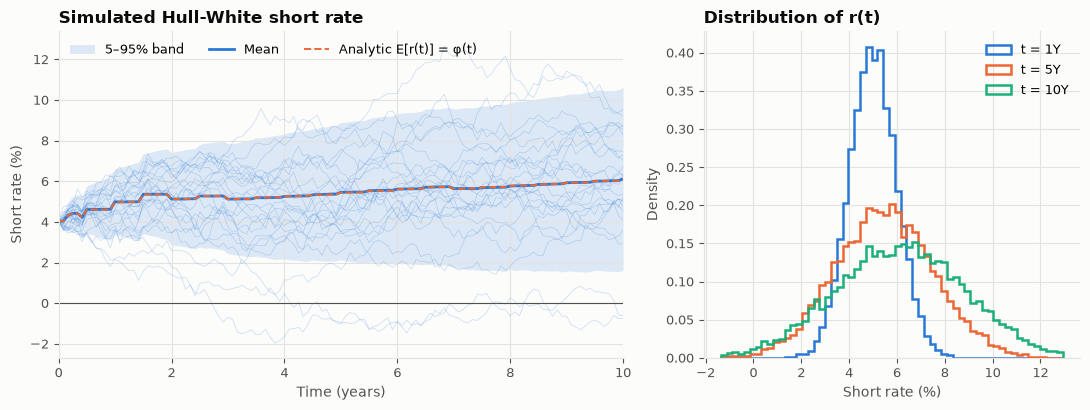

In [3]:
short_rates = paths.short_rates(curve)
analytic_mean = curve.inst_forward(grid) + phi_adjustment(HW_PARAMS, grid)
fig = plot_rate_paths(grid, short_rates, analytic_mean)

The mean follows $\varphi(t)$, which is stepwise because the curve's forwards are piecewise flat. The spread grows like $\sigma\sqrt{(1-e^{-2at})/2a}$, slightly slower than $\sigma\sqrt{t}$ because of mean reversion. Hull-White is a Gaussian model, so rates can go negative; the table shows how often.

## 2. Does the simulation do what the model says?

### Moments vs analytic values

In [4]:
rate_distribution_table(curve, paths)

,time,mean_mc,mean_analytic,std_mc,std_analytic,p05,p95,prob_negative
0,0.500000,0.046097,0.046023,0.007024,0.007018,0.034545,0.057657,0.000000
1,1.000000,0.049872,0.049714,0.009846,0.009852,0.033714,0.066086,0.000000
2,2.000000,0.051236,0.051253,0.013825,0.013728,0.028753,0.073966,0.000200
3,5.000000,0.054575,0.054416,0.020539,0.020784,0.021439,0.088937,0.003600
4,10.000000,0.061150,0.061151,0.027424,0.027422,0.016141,0.106092,0.012800


### Mean reversion

$E[x(t+h)\mid x(t)] = x(t)\,e^{-ah}$, so regressing $x(t+h)$ on $x(t)$ across paths should give slope $e^{-ah}$. With weak mean reversion ($a$ = 3%) the slopes sit close to 1 and the estimate is noisy, so the table shows standard errors. At 10,000 paths one row lands about 3 standard errors out; rerunning with 400,000 paths puts all three within 0.6 standard errors. The precise test is in `tests/test_rate_models.py`, which uses $a$ = 0.5.

In [5]:
rows = []
for t, h in [(1.0, 1.0), (2.0, 3.0), (3.0, 5.0)]:
    now, later = paths.x[:, time_index(grid, t)[0]], paths.x[:, time_index(grid, t + h)[0]]
    slope = np.dot(now, later) / np.dot(now, now)
    se = np.std(later - slope * now) / np.sqrt(np.dot(now, now))
    target = np.exp(-HW_PARAMS.mean_reversion * h)
    rows.append({'t': t, 'h': h, 'slope_mc': slope, 'exp(-a h)': target, 'std_error': se, 'z_score': (slope - target) / se})
pd.DataFrame(rows)

,t,h,slope_mc,exp(-a h),std_error,z_score
0,1.000000,1.000000,0.982146,0.970446,0.010031,1.166495
1,2.000000,3.000000,0.876623,0.913931,0.011994,-3.110562
2,3.000000,5.000000,0.843592,0.860708,0.012661,-1.351811


### Martingale check: the simulated model reprices today's curve

In an arbitrage-free model, discounted bond prices are martingales: $E[D(0,t)P(t,T)] = P(0,T)$. A |z| well above 3 would point to a bug in the bond formula, the discounting or the simulation.

In [6]:
martingale_table(curve, paths)

,t,T,"mc_E[D(0,t)P(t,T)]","curve_P(0,T)",std_error,z_score
0,1.000000,2.000000,0.908541,0.908760,0.000135,-1.619765
1,1.000000,5.000000,0.777709,0.778240,0.000328,-1.619938
2,2.000000,10.000000,0.591220,0.591196,0.000667,0.036951
3,5.000000,10.000000,0.590524,0.591196,0.000891,-0.753883
4,10.000000,10.000000,0.590960,0.591196,0.000967,-0.243944


## 3. Revaluing the portfolio on every path

At each grid date $t$, $P(t,T)$ is computed for every future portfolio date. Each swap is then priced with the **same leg formulas as the time-0 pricer**. A floating coupon fixes on its reset date at $L_j = (1/P(S_j,T_j)-1)/\tau_j$, and that fixing is used while the coupon is running. $V(t)$ excludes cash flows paid at $t$.

In [7]:
cube = revalue_portfolio(portfolio, curve, paths)
time_zero = np.array([swap_mtm(s, curve) for s in portfolio])
print('cube shape (trades, paths, dates):', cube.shape)
print('max |cube(t=0) - time-0 pricer| =', np.abs(cube[:, :, 0] - time_zero[:, None]).max())

cube shape (trades, paths, dates): (10, 10000, 121)
max |cube(t=0) - time-0 pricer| = 3.725290298461914e-09


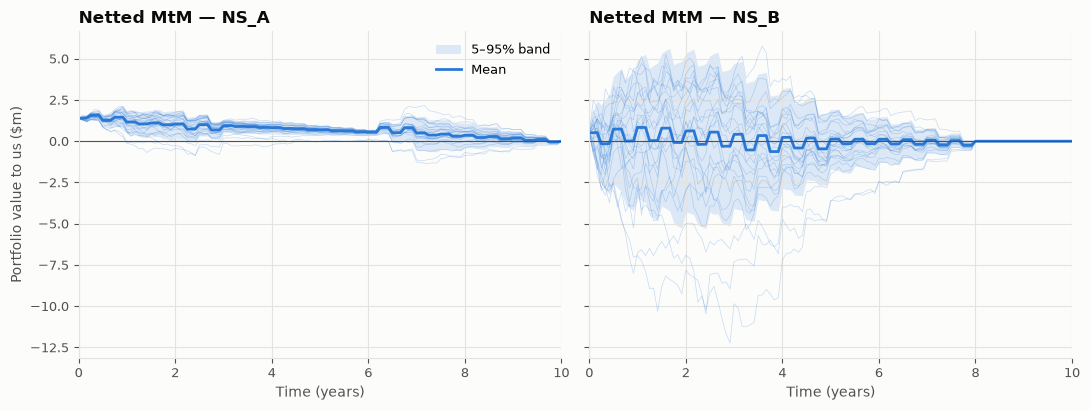

In [8]:
mtm_by_set = netting_set_mtm(cube, portfolio)
fig = plot_mtm_fan(grid, mtm_by_set)

In [9]:
percentile_profile(grid, mtm_by_set)

,netting_set_id,time,mean,p05,p95
0,NS_A,0.500000,"1,258,048.801183","869,194.838793","1,627,139.550757"
1,NS_A,1.000000,"1,157,054.268198","454,258.808198","1,827,280.428700"
2,NS_A,2.000000,"1,037,840.355914","189,384.477794","1,846,509.666459"
3,NS_A,5.000000,"690,036.382895","399,781.670403","923,080.241987"
4,NS_A,10.000000,0.000000,0.000000,0.000000
5,NS_B,0.500000,"729,251.925228","-2,572,276.387764","3,917,872.426354"
6,NS_B,1.000000,"838,045.889445","-3,433,096.625518","4,931,702.749871"
7,NS_B,2.000000,"617,450.003127","-4,290,201.949944","5,321,432.577424"
8,NS_B,5.000000,"121,082.334474","-1,700,237.645751","1,901,034.736403"
9,NS_B,10.000000,0.000000,0.000000,0.000000


**Reading the chart**

- **NS_A** mixes payers and receivers across similar maturities, so its parallel rate risk mostly cancels and its value barely moves. A one-factor model moves all rates together and cannot produce curve twists, so it **understates** the risk of a curve-hedged book like this one. That is a model limitation, not a property of the trades.
- **NS_B** is mostly payers. It gains when rates rise and loses when they fall, so its value is widely dispersed.
- **Sawtooth:** the fixed leg pays semiannually and the floating leg quarterly. On a floating-only date we receive a coupon and value drops; on a joint date we also pay the larger fixed coupon and value jumps back up.
- **Shape over time:** dispersion first grows as rates diffuse, then shrinks as cash flows run off. Every trade is worth zero after its final payment. Phase C turns these values into exposure with $\max(V,0)$.